# Model Neural dan Regularisasi

Klasifikasi cognitive load Low, Medium, dan High dari fitur eye tracking dan HRV. Window 15, 25, dan 45 detik dibandingkan dengan pembagian data yang sama.

## Konfigurasi

Dataset dan hasil eksperimen disimpan pada Google Drive. Tentukan lokasi proyek dan folder run bila melanjutkan eksperimen yang terputus.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Penelitian-Adaptive-IDE")
DATASET_ROOT = PROJECT_ROOT / "Dataset" / "v2_session_phase"
RESUME_DIR = None
EXPERIMENT = "exp02"

In [2]:
import importlib.metadata as _metadata
import importlib.util as _import_util
import subprocess
import sys

if sys.version_info < (3, 12):
    raise RuntimeError("Gunakan runtime Colab dengan Python 3.12 atau lebih baru.")

# Versi dependency dicatat bersama hasil eksperimen.
_required = {
    "numpy": "2.5.1",
    "pandas": "3.0.3",
    "scipy": "1.18.0",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.0",
    "cloudpickle": "3.1.3",
}
if EXPERIMENT == "exp01":
    _required.update({"xgboost": "3.4.1", "catboost": "1.2.10"})
_imports = {"scikit-learn": "sklearn", "imbalanced-learn": "imblearn"}
_changes = []
_restart = False
_current: str | None
for _name, _version in _required.items():
    try:
        _current = _metadata.version(_name)
    except _metadata.PackageNotFoundError:
        _current = None
    if _current != _version:
        _changes.append(f"{_name}=={_version}")
        _restart = _restart or _imports.get(_name, _name) in sys.modules
if _changes:
    print("Menyiapkan dependency:", ", ".join(_changes))
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *_changes]
    )  # nosec B603
    if _restart:
        raise RuntimeError(
            "Dependency diperbarui. Pilih Runtime > Restart session, lalu Run all kembali."
        )
if EXPERIMENT == "exp02" and _import_util.find_spec("torch") is None:
    raise RuntimeError(
        "PyTorch tidak tersedia. Gunakan runtime Colab standar yang sudah menyertakan PyTorch."
    )

try:
    _in_colab = _import_util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    _in_colab = False
if _in_colab:
    from google.colab import drive

    drive.mount("/content/drive")

print("Dependency siap. Path proyek:", PROJECT_ROOT)

Mounted at /content/drive
Dependency siap. Path proyek: /content/drive/MyDrive/Penelitian-Adaptive-IDE


In [3]:
import copy
import hashlib
import io
import json
import platform
import random
import tempfile
import time
from datetime import UTC, datetime
from functools import partial
from importlib import metadata
from pathlib import Path
from typing import Any

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

LABELS = ["Low", "Medium", "High"]
SEED = 42
CODE_VERSION = "batch04-2.0.0"
SENSOR_FEATURES = [
    "rmssd_ms",
    "sdnn_ms",
    "rmssd_baseline_ratio",
    "blink_count",
    "blink_rate_per_minute",
    "ear_left_mean",
    "ear_left_std",
    "ear_right_mean",
    "ear_right_std",
    "iris_size_estimate_mean",
    "iris_size_estimate_std",
    "iris_size_delta_mean",
    "iris_size_delta_std",
    "head_pitch_mean",
    "head_pitch_std",
    "head_yaw_mean",
    "head_yaw_std",
    "gaze_x_norm_mean",
    "gaze_x_norm_std",
    "gaze_y_norm_mean",
    "gaze_y_norm_std",
    "eye_state_fixation_ratio",
    "eye_state_saccade_ratio",
    "eye_state_transition_ratio",
    "eye_state_unclassified_ratio",
    "eye_state_other_ratio",
]
EYE_FEATURES = [
    f
    for f in SENSOR_FEATURES
    if f
    not in {
        "rmssd_ms",
        "sdnn_ms",
        "rmssd_baseline_ratio",
        "blink_count",
        "eye_state_other_ratio",
    }
]
GROUPS = {
    "eye": EYE_FEATURES,
    "hrv": ["rmssd_ms", "sdnn_ms"],
    "fusion": ["rmssd_ms", "sdnn_ms"] + EYE_FEATURES,
}


def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()


try:
    from IPython.display import display
except ImportError:
    display = print

IMPLEMENTATION_HASH = "bb8d769128b074bd94e0288804ffb8a8849e7daf4a2a51116b088d0d36cb478f"

## Dataset dan Pembagian Data

Test menggunakan blok waktu tetap dari evaluasi sebelumnya. Sisa data dipisahkan menjadi Train dan validation akhir. Di dalam Train, lima fold bergantian menjadi validation internal, sehingga setiap baris mendapat satu prediksi out-of-fold.

Blok berdurasi 120 detik tidak dipecah antarbagian. Purge 45 detik mencegah dukungan sensor yang overlap masuk ke bagian berbeda, termasuk antarwindow. Stratifikasi memperhitungkan kelas dan sesi bila jumlah blok mencukupi. Identitas, fase, soal, dan timestamp tidak menjadi predictor classifier. Evaluasi ini bersifat internal pada dataset yang telah digunakan sebelumnya.

In [4]:
def prepare_views(frames):
    """Split metadata-only; tidak menggunakan nilai fitur untuk penempatan blok."""
    if set(frames) != {15, 25, 45}:
        raise ValueError("Ketiga CSV window 15, 25, dan 45 detik harus tersedia.")
    clean: dict[int, Any] = {}
    union: dict[tuple[str, int], str] = {}
    anchors: dict[str, int] = {}
    people: dict[str, str] = {}
    required = set(
        SENSOR_FEATURES
        + [
            "participant_id",
            "session_id",
            "window_start",
            "window_end",
            "window_seconds",
            "cognitive_load_label",
        ]
    )
    for window in (15, 25, 45):
        df = frames[window].copy()
        missing = required - set(df)
        if missing or df.empty:
            raise ValueError(
                f"Window {window}: kolom hilang {sorted(missing)} atau CSV kosong."
            )
        for field in ("session_id", "participant_id"):
            if df[field].isna().any() or df[field].astype(str).str.strip().eq("").any():
                raise ValueError(f"Window {window}: {field} kosong.")
            df[field] = df[field].astype(str)
        if not df["cognitive_load_label"].isin(LABELS).all():
            raise ValueError(f"Window {window}: label tidak dikenal atau kosong.")
        try:
            start = pd.to_datetime(
                df["window_start"], utc=True, errors="raise", format="ISO8601"
            )
            end = pd.to_datetime(
                df["window_end"], utc=True, errors="raise", format="ISO8601"
            )
            df["_start_ns"] = start.dt.as_unit("ns").astype("int64")
            df["_end_ns"] = end.dt.as_unit("ns").astype("int64")
        except (ValueError, TypeError) as exc:
            raise ValueError(f"Window {window}: timestamp tidak valid.") from exc
        if start.isna().any() or end.isna().any():
            raise ValueError("Timestamp kosong.")
        duration = (end - start).dt.total_seconds().to_numpy()
        if not np.allclose(duration, window, atol=0.001, rtol=0):
            raise ValueError(
                f"Window {window}: rentang timestamp bukan {window} detik."
            )
        if not pd.to_numeric(df["window_seconds"], errors="coerce").eq(window).all():
            raise ValueError(f"Window {window}: window_seconds tidak cocok.")
        if df.duplicated(["session_id", "_end_ns"]).any():
            raise ValueError(f"Window {window}: endpoint ganda.")
        for field in SENSOR_FEATURES:
            df[field] = pd.to_numeric(df[field], errors="coerce").replace(
                [np.inf, -np.inf], np.nan
            )
        df["_y"] = df["cognitive_load_label"].map(
            {label: i for i, label in enumerate(LABELS)}
        )
        df = df.sort_values(["session_id", "_end_ns"]).reset_index(drop=True)
        for row in df[
            [
                "session_id",
                "participant_id",
                "_start_ns",
                "_end_ns",
                "cognitive_load_label",
            ]
        ].itertuples(index=False, name=None):
            sid, person, first, last, label = row
            key = (sid, int(last))
            if key in union and union[key] != label:
                raise ValueError("Label endpoint bertentangan antarwindow.")
            if sid in people and people[sid] != person:
                raise ValueError("Satu session_id terhubung ke beberapa peserta.")
            people[sid] = person
            union[key] = label
            anchors[sid] = min(anchors.get(sid, int(first)), int(first))
        clean[window] = df

    blocks: dict[tuple[str, int], list[tuple[tuple[str, int], str]]] = {}
    for key, label in sorted(union.items()):
        block = (key[0], (key[1] - anchors[key[0]]) // 120_000_000_000)
        blocks.setdefault(block, []).append((key, label))
    buckets: dict[str, list[tuple[str, int]]] = {}
    for block, members in sorted(blocks.items()):
        counts: dict[str, int] = {}
        for _, label in members:
            counts[label] = counts.get(label, 0) + 1
        dominant = min(counts, key=lambda label: (-counts[label], label))
        buckets.setdefault(dominant, []).append(block)
    rng = random.Random(SEED)
    assignment = {}
    for label, group in sorted(buckets.items()):
        rng.shuffle(group)
        n = max(1, round(len(group) * 0.15))
        if len(group) < 3:
            raise ValueError("Blok terlalu sedikit untuk membentuk tiga bagian.")
        for i, block in enumerate(group):
            part = "test" if i < n else "validation" if i < 2 * n else "train"
            for key, _ in blocks[block]:
                assignment[key] = part

    def close_to(key, index):
        values = index.get(key[0], np.array([], dtype=np.int64))
        if not len(values):
            return False
        pos = np.searchsorted(values, key[1])
        return any(
            abs(int(values[j]) - key[1]) < 45_000_000_000
            for j in (pos - 1, pos)
            if 0 <= j < len(values)
        )

    def index_for(parts):
        index: dict[str, list[int]] = {}
        for sid, last in parts:
            index.setdefault(sid, []).append(last)
        return {
            sid: np.array(sorted(values), dtype=np.int64)
            for sid, values in index.items()
        }

    kept = {key: part for key, part in assignment.items() if part == "test"}
    test_index = index_for(kept)
    kept.update(
        {
            key: part
            for key, part in assignment.items()
            if part == "validation" and not close_to(key, test_index)
        }
    )
    held_index = index_for(kept)
    kept.update(
        {
            key: part
            for key, part in assignment.items()
            if part == "train" and not close_to(key, held_index)
        }
    )
    manifest = [
        {
            "session_id": key[0],
            "end_ns": key[1],
            "assigned": assignment[key],
            "split": kept.get(key, "purged"),
        }
        for key in sorted(union)
    ]
    summary = []
    for window, df in clean.items():
        df["_split"] = [
            kept.get((sid, int(last)), "purged")
            for sid, last in zip(df["session_id"], df["_end_ns"], strict=True)
        ]
        for part in ("train", "validation", "test", "purged"):
            subset = df[df["_split"] == part]
            class_counts = subset["cognitive_load_label"].value_counts()
            if part != "purged" and not set(LABELS).issubset(class_counts.index):
                raise ValueError(
                    f"Window {window}: {part} tidak mempunyai ketiga kelas."
                )
            summary.append(
                {
                    "window_seconds": window,
                    "split": part,
                    "rows": len(subset),
                    **{label: int(class_counts.get(label, 0)) for label in LABELS},
                }
            )
    return clean, manifest, pd.DataFrame(summary)


N_FOLDS = 5
NORMALIZATIONS = ("global", "session_center", "session_zscore")
GROUPS["nonspatial"] = GROUPS["hrv"] + [
    c
    for c in EYE_FEATURES
    if c == "blink_rate_per_minute" or c.startswith(("ear_", "iris_"))
]
RELATIVE_FEATURES = ["hrv_ratio", "ear_relative_gap", "ear_variation", "iris_variation"]
GROUPS["relative"] = GROUPS["fusion"] + RELATIVE_FEATURES


def purge_against(frame, held):
    """Remove training endpoints with overlapping conservative 45-second support."""
    keep = []
    for sid, subset in frame.groupby("session_id", sort=True):
        times = np.sort(held.loc[held.session_id.eq(sid), "_end_ns"].to_numpy())
        ends = subset._end_ns.to_numpy()
        if not len(times):
            keep.extend(subset.index)
            continue
        pos = np.searchsorted(times, ends)
        left = times[np.maximum(pos - 1, 0)]
        right = times[np.minimum(pos, len(times) - 1)]
        good = (np.abs(ends - left) >= 45_000_000_000) & (
            np.abs(ends - right) >= 45_000_000_000
        )
        keep.extend(subset.index[good])
    return frame.loc[sorted(keep)]


def block_folds(frame):
    """Balance session/class strata where supported, without splitting time blocks."""
    if frame._block.nunique() < N_FOLDS:
        raise ValueError("Blok training terlalu sedikit untuk lima fold.")
    counts = frame.groupby(["session_id", "cognitive_load_label"])._block.nunique()
    strata = np.array(
        [
            f"session::{sid}::{label}"
            if counts[(sid, label)] >= N_FOLDS
            else f"global::{label}"
            for sid, label in zip(
                frame.session_id, frame.cognitive_load_label, strict=True
            )
        ],
        dtype=object,
    )
    for label in LABELS:
        rare = int((strata == f"global::{label}").sum())
        if 0 < rare < N_FOLDS:
            strata[frame.cognitive_load_label.eq(label).to_numpy()] = f"global::{label}"
    return list(
        StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=42).split(
            np.zeros(len(frame)), strata, frame._block
        )
    )


def endpoint_keys(frame):
    return set(zip(frame.session_id, frame._end_ns.astype(int), strict=True))


def prepare_experiment(frames):
    views, legacy_outer, _ = prepare_views(frames)
    combined = pd.concat(views.values(), ignore_index=True)
    anchors = combined.groupby("session_id")._start_ns.min()
    union = (
        combined.drop_duplicates(["session_id", "_end_ns"])
        .sort_values(["session_id", "_end_ns"])
        .copy()
    )
    union["_block"] = pd.factorize(
        pd.MultiIndex.from_arrays(
            [
                union.session_id,
                (union._end_ns - union.session_id.map(anchors)) // 120_000_000_000,
            ]
        ),
        sort=True,
    )[0]
    test = union[union._split.eq("test")]
    development = purge_against(union[~union._split.eq("test")], test)
    train_idx, selection_idx = block_folds(development)[0]
    selection = development.iloc[selection_idx]
    train = purge_against(development.iloc[train_idx], selection)
    main = {
        **dict.fromkeys(endpoint_keys(train), "train"),
        **dict.fromkeys(endpoint_keys(selection), "validation"),
        **dict.fromkeys(endpoint_keys(test), "test"),
    }
    folds, monitors = [], []
    for fitting_idx, scoring_idx in block_folds(train):
        scoring = train.iloc[scoring_idx]
        fitting = purge_against(train.iloc[fitting_idx], scoring)
        monitor_fit_idx, monitor_idx = block_folds(fitting)[0]
        monitor = fitting.iloc[monitor_idx]
        monitor_fit = purge_against(fitting.iloc[monitor_fit_idx], monitor)
        folds.append(
            {
                **dict.fromkeys(endpoint_keys(fitting), "train"),
                **dict.fromkeys(endpoint_keys(scoring), "validation"),
            }
        )
        monitors.append(
            {
                **dict.fromkeys(endpoint_keys(monitor_fit), "fit"),
                **dict.fromkeys(endpoint_keys(monitor), "monitor"),
            }
        )
    summaries = []
    for window, view in views.items():
        keys = list(zip(view.session_id, view._end_ns.astype(int), strict=True))
        view["_split"] = [main.get(k, "purged") for k in keys]
        view["_block"] = list(
            zip(
                view.session_id,
                (
                    (view._end_ns - view.session_id.map(anchors)) // 120_000_000_000
                ).astype(int),
                strict=True,
            )
        )
        for fold in range(N_FOLDS):
            view[f"_fold_{fold}"] = [folds[fold].get(k, "purged") for k in keys]
            view[f"_monitor_{fold}"] = [monitors[fold].get(k, "purged") for k in keys]
        partitions = [
            ("outer", -1, part, outer_frame(view, part))
            for part in ("train", "validation", "test", "purged")
        ]
        for fold in range(N_FOLDS):
            partitions.extend(
                ("inner", fold, part, fold_frame(view, fold, part))
                for part in ("train", "validation")
            )
            partitions.extend(
                ("monitor", fold, part, view[view[f"_monitor_{fold}"].eq(part)])
                for part in ("fit", "monitor")
            )
        for level, fold, part, sub in partitions:
            counts = sub.cognitive_load_label.value_counts()
            if part != "purged" and not set(LABELS).issubset(counts.index):
                raise ValueError(
                    f"Window {window}, {level}/{fold}/{part}: kelas tidak lengkap."
                )
            summaries.append(
                {
                    "window": window,
                    "level": level,
                    "fold": fold,
                    "split": part,
                    "rows": len(sub),
                    **{label: int(counts.get(label, 0)) for label in LABELS},
                }
            )
        hits = sum(
            view[f"_fold_{i}"].eq("validation").astype(int) for i in range(N_FOLDS)
        )
        if not hits.loc[view._split.eq("train")].eq(1).all():
            raise ValueError("Cakupan out-of-fold tidak tepat satu kali.")

    def manifest_rows(assignment):
        return [
            {
                "session_id": sid,
                "end_ns": int(last),
                "split": assignment.get((sid, int(last)), "purged"),
            }
            for sid, last in union[["session_id", "_end_ns"]].itertuples(
                index=False, name=None
            )
        ]

    manifest = {
        "schema_version": 2,
        "seed": 42,
        "n_folds": N_FOLDS,
        "block_seconds": 120,
        "support_seconds": 45,
        "legacy_outer": legacy_outer,
        "outer": manifest_rows(main),
        "inner": [manifest_rows(a) for a in folds],
        "monitor": [manifest_rows(a) for a in monitors],
    }
    return views, manifest, pd.DataFrame(summaries)


def outer_frame(view, part):
    return view.loc[view._split.eq(part)].reset_index(drop=True)


def fold_frame(view, fold, part):
    if part == "test":
        return outer_frame(view, "test")
    return view.loc[view[f"_fold_{fold}"].eq(part)].reset_index(drop=True)


def read_datasets(dataset_root):
    frames, hashes = {}, {}
    for window in (15, 25, 45):
        payload = (
            Path(dataset_root) / f"window_{window}s_step_5s" / "good_acceptable.csv"
        ).read_bytes()
        hashes[str(window)] = hashlib.sha256(payload).hexdigest()
        frames[window] = pd.read_csv(io.BytesIO(payload))
    views, manifest, summary = prepare_experiment(frames)
    return views, manifest, summary, hashes

In [5]:
views, split_manifest, split_counts, dataset_hashes = read_datasets(DATASET_ROOT)
display(split_counts[split_counts.level.eq("outer")])
display(split_counts[split_counts.level.eq("inner")])
distribution = pd.DataFrame(
    {
        f"{w}s": d.cognitive_load_label.value_counts().reindex(LABELS)
        for w, d in views.items()
    }
)
display(distribution)

,window,level,fold,split,rows,Low,Medium,High
0,15,outer,-1,train,2069,599,764,706
1,15,outer,-1,validation,560,168,198,194
2,15,outer,-1,test,464,141,173,150
3,15,outer,-1,purged,486,154,131,201
24,25,outer,-1,train,1845,546,663,636
25,25,outer,-1,validation,489,153,157,179
26,25,outer,-1,test,423,133,161,129
27,25,outer,-1,purged,457,152,112,193
48,45,outer,-1,train,1444,492,463,489
49,45,outer,-1,validation,373,137,88,148


,window,level,fold,split,rows,Low,Medium,High
4,15,inner,0,train,1494,424,582,488
5,15,inner,0,validation,412,125,135,152
8,15,inner,1,train,1480,433,512,535
9,15,inner,1,validation,407,123,165,119
12,15,inner,2,train,1455,447,512,496
13,15,inner,2,validation,424,111,168,145
16,15,inner,3,train,1495,450,533,512
17,15,inner,3,validation,417,118,158,141
20,15,inner,4,train,1479,433,542,504
21,15,inner,4,validation,409,122,138,149


,15s,25s,45s
cognitive_load_label,,,
Low,1062,984,908
Medium,1266,1093,728
High,1251,1137,891


## Prapemrosesan dan Representasi Sensor

Skala global, pemusatan per sesi, dan standardisasi per sesi dibandingkan sebagai cabang terpisah. Imputer, scaler, serta acuan sesi hanya dipelajari dari training. Sesi tanpa acuan menggunakan statistik global training.

Fusion memakai 23 fitur; nonspatial memakai 11 fitur tanpa posisi gaze, orientasi kepala, dan rasio keadaan mata. Empat fitur relatif mengukur hubungan RMSSD–SDNN, perbedaan EAR, variasi EAR, dan variasi ukuran iris. Pembagi mendekati nol diperlakukan sebagai missing value. Nilai negatif hasil pemusatan tetap sah.

In [6]:
def raw_sensor_input(frame, columns):
    x = (
        frame[columns]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .reset_index(drop=True)
    )
    for name in ("rmssd_ms", "sdnn_ms", "rmssd_baseline_ratio"):
        if name in x:
            x.loc[x[name] < 0, name] = np.nan
    return x


def sensor_features(frame, columns):
    requested = list(columns)
    if not set(requested).intersection(RELATIVE_FEATURES):
        return raw_sensor_input(frame, requested)
    dependencies = {
        "hrv_ratio": ["rmssd_ms", "sdnn_ms"],
        "ear_relative_gap": ["ear_left_mean", "ear_right_mean"],
        "ear_variation": [
            "ear_left_mean",
            "ear_right_mean",
            "ear_left_std",
            "ear_right_std",
        ],
        "iris_variation": ["iris_size_estimate_mean", "iris_size_estimate_std"],
    }
    needed = [c for c in requested if c not in RELATIVE_FEATURES]
    for name in requested:
        needed.extend(dependencies.get(name, []))
    raw = raw_sensor_input(frame, list(dict.fromkeys(needed)))

    def divide(numerator, denominator):
        return numerator / denominator.where(denominator.abs() > 1e-6)

    derived = {}
    if "hrv_ratio" in requested:
        derived["hrv_ratio"] = divide(raw.rmssd_ms, raw.sdnn_ms)
    if {"ear_relative_gap", "ear_variation"}.intersection(requested):
        ear_sum = raw.ear_left_mean.abs() + raw.ear_right_mean.abs()
        if "ear_relative_gap" in requested:
            derived["ear_relative_gap"] = divide(
                2 * (raw.ear_left_mean - raw.ear_right_mean), ear_sum
            )
        if "ear_variation" in requested:
            derived["ear_variation"] = divide(
                raw.ear_left_std + raw.ear_right_std, ear_sum
            )
    if "iris_variation" in requested:
        derived["iris_variation"] = divide(
            raw.iris_size_estimate_std, raw.iris_size_estimate_mean.abs()
        )
    return raw.assign(**derived)[requested].replace([np.inf, -np.inf], np.nan)


class SessionPreprocessor:
    def __init__(self, columns, normalization="global", selector="all"):
        self.columns = list(columns)
        self.normalization = normalization
        self.selector = selector

    def _normalize(self, frame):
        x = sensor_features(frame, self.columns)
        if self.normalization != "global":
            sid = frame["session_id"].astype(str)
            center = (
                self.centers_.reindex(sid)
                .reset_index(drop=True)
                .fillna(self.global_center_)
            )
            x = x - center
            if self.normalization == "session_zscore":
                scale = (
                    self.scales_.reindex(sid)
                    .reset_index(drop=True)
                    .fillna(self.global_scale_)
                )
                x = x / scale
        # Negative HRV after centering is valid. Physical checks belong above.
        return x

    def fit(self, frame, y=None):
        if self.normalization not in NORMALIZATIONS or self.selector not in (
            "all",
            "mi8",
        ):
            raise ValueError("Normalisasi/seleksi fitur tidak dikenal.")
        x = sensor_features(frame, self.columns)
        sid = frame["session_id"].astype(str).to_numpy()
        self.global_center_ = x.mean().fillna(0)
        self.global_scale_ = x.std(ddof=0).where(lambda s: s > 1e-10, 1).fillna(1)
        self.centers_ = (
            x.assign(_session=sid)
            .groupby("_session")
            .mean()
            .fillna(self.global_center_)
        )
        self.scales_ = x.assign(_session=sid).groupby("_session").std(ddof=0)
        self.scales_ = self.scales_.where(self.scales_ > 1e-10).fillna(
            self.global_scale_
        )
        steps = [
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]
        if self.selector == "mi8":
            steps.append(
                (
                    "selector",
                    SelectKBest(
                        partial(mutual_info_classif, random_state=42),
                        k=min(8, len(self.columns)),
                    ),
                )
            )
        self.pipeline_ = Pipeline(steps).fit(self._normalize(frame), y)
        return self

    def transform(self, frame):
        result = self.pipeline_.transform(self._normalize(frame))
        if not np.isfinite(result).all():
            raise ValueError("Hasil preprocessing nonfinite.")
        return result

    def fit_transform(self, frame, y=None):
        return self.fit(frame, y).transform(frame)


def metric_labels(y, predicted):
    return {
        "accuracy": float(accuracy_score(y, predicted)),
        "macro_f1": float(
            f1_score(y, predicted, labels=[0, 1, 2], average="macro", zero_division=0)
        ),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
    }


def rank_key(record):
    return (
        -record["validation"]["accuracy"],
        -record["validation"]["macro_f1"],
        record.get("accuracy_std", 0),
        record.get("complexity", 1),
        record["id"],
    )


def vote_predictions(values):
    votes = np.asarray(values, dtype=int)
    if votes.ndim != 2 or not len(votes) or not np.isin(votes, [0, 1, 2]).all():
        raise ValueError("Vote tidak valid.")
    counts = np.stack([(votes == c).sum(axis=0) for c in range(3)], axis=1)
    tied = counts == counts.max(axis=1, keepdims=True)
    labels = np.full(votes.shape[1], -1, dtype=int)
    for component in votes:
        choose = (labels < 0) & tied[np.arange(len(labels)), component]
        labels[choose] = component[choose]
    return {
        "labels": labels,
        "scores": counts / len(votes),
        "score_type": "vote_fraction",
    }


def combine_outputs(outputs, kind):
    if kind == "vote":
        return vote_predictions([o["labels"] for o in outputs])
    if any(o["score_type"] != "probability" for o in outputs):
        raise ValueError(
            "Decision score/vote tidak boleh dirata-ratakan sebagai probabilitas."
        )
    probabilities = np.mean([o["scores"] for o in outputs], axis=0)
    return {
        "labels": probabilities.argmax(1),
        "scores": probabilities,
        "score_type": "probability",
    }


def encode_model(model):
    result = dict(model)
    if model["kind"] in ("vote", "probability_average"):
        result["models"] = [encode_model(child) for child in model["models"]]
    elif model["kind"] == "tabular" and model["recipe"]["family"] in (
        "xgboost",
        "catboost",
    ):
        family = model["recipe"]["family"]
        if family == "xgboost":
            payload = bytes(
                model["estimator"].get_booster().save_raw(raw_format="json")
            )
        else:
            with tempfile.TemporaryDirectory() as folder:
                path = Path(folder) / "model.cbm"
                model["estimator"].save_model(str(path))
                payload = path.read_bytes()
        result.pop("estimator")
        result["native_model"] = payload
    return result


def decode_model(model):
    result = dict(model)
    if model["kind"] in ("vote", "probability_average"):
        result["models"] = [decode_model(child) for child in model["models"]]
    elif "native_model" in model:
        family = model["recipe"]["family"]
        if family == "xgboost":
            from xgboost import XGBClassifier

            estimator = XGBClassifier()
            estimator.load_model(bytearray(model["native_model"]))
        else:
            from catboost import CatBoostClassifier

            estimator = CatBoostClassifier()
            with tempfile.TemporaryDirectory() as folder:
                path = Path(folder) / "model.cbm"
                path.write_bytes(model["native_model"])
                estimator.load_model(str(path))
        result.pop("native_model")
        result["estimator"] = estimator
    return result


def dump_bundle(model):
    return cloudpickle.dumps(encode_model(model))


def load_bundle(payload):
    # Only load trusted model bundles produced by the research team.
    return decode_model(cloudpickle.loads(payload))  # nosec B301


def native_artifacts(model):
    result = {}

    def visit(item, name):
        if item["kind"] in ("vote", "probability_average"):
            for i, child in enumerate(item["models"]):
                visit(child, f"{name}_{i}")
        elif item["kind"] == "tabular" and item["recipe"]["family"] in (
            "xgboost",
            "catboost",
        ):
            suffix = "json" if item["recipe"]["family"] == "xgboost" else "cbm"
            result[f"{name}.{suffix}"] = encode_model(item)["native_model"]

    visit(model, "native")
    return result


def prediction_bytes(result):
    stream = io.BytesIO()
    np.savez(
        stream,
        labels=result["labels"],
        scores=result["scores"],
        score_type=result["score_type"],
    )
    return stream.getvalue()


def read_prediction(payload):
    with np.load(io.BytesIO(payload), allow_pickle=False) as archive:
        return {
            "labels": archive["labels"],
            "scores": archive["scores"],
            "score_type": str(archive["score_type"]),
        }


def candidate_shortlist(records):
    result = []
    for normalization in NORMALIZATIONS:
        families = set()
        for record in sorted(records, key=rank_key):
            recipe = record["recipe"]
            family = recipe["family"]
            if (
                recipe.get("normalization") != normalization
                or family == "dummy"
                or family in families
            ):
                continue
            families.add(family)
            result.append(record)
            if len(families) == 2:
                break
    return result


def normalization_leaders(records):
    leaders = []
    for norm in NORMALIZATIONS:
        group = [
            r
            for r in records
            if r["recipe"].get("normalization") == norm
            and r["recipe"]["family"] != "dummy"
        ]
        if group:
            leaders.append(min(group, key=rank_key))
    return leaders

In [7]:
ARTIFACT_IO_REVISION = 2


class ArtifactStore:
    """Checkpoint lokal; salinan Drive diverifikasi sebelum completion marker."""

    def __init__(self, local, remote, signature):
        self.local, self.remote = Path(local), Path(remote)
        self.signature = signature
        self.local.mkdir(parents=True, exist_ok=True)
        self.remote.mkdir(parents=True, exist_ok=True)
        identity = self.remote / "run.json"
        expected = {"signature": signature}
        if identity.exists():
            if json.loads(identity.read_text(encoding="utf-8")) != expected:
                raise ValueError(
                    "Resume ditolak: dataset, split, konfigurasi, atau environment berubah."
                )
        else:
            self._copy_verified(identity, canonical(expected).encode())

    def _copy_verified(self, target, payload):
        for attempt in range(5):
            try:
                target.parent.mkdir(parents=True, exist_ok=True)
                # Tidak mengandalkan atomic rename pada mount Google Drive.
                with target.open("wb") as handle:
                    handle.write(payload)
                    handle.flush()
                if (
                    hashlib.sha256(target.read_bytes()).digest()
                    != hashlib.sha256(payload).digest()
                ):
                    raise OSError(f"Checksum salinan tidak cocok: {target}")
                return
            except OSError:
                if attempt == 4:
                    raise
                time.sleep(0.5 * (2**attempt))

    def _folder(self, key):
        if not key or any(
            c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
            for c in key
        ):
            raise ValueError("ID artefak tidak valid.")
        return self.remote / key

    def commit(self, key, record, artifacts=None):
        folder = self._folder(key)
        artifacts = dict(artifacts or {})
        artifacts["record.json"] = canonical(record).encode()
        for name in artifacts:
            if Path(name).name != name or name in {
                "",
                ".",
                "..",
                "done.json",
                "run.json",
            }:
                raise ValueError("Nama artefak tidak valid.")
        checksums = {
            name: hashlib.sha256(payload).hexdigest()
            for name, payload in artifacts.items()
        }
        marker = canonical(
            {"checksums": checksums, "io_revision": ARTIFACT_IO_REVISION}
        ).encode()
        for name, payload in artifacts.items():
            self._copy_verified(self.local / key / name, payload)
        self._copy_verified(self.local / key / "done.json", marker)
        for name, payload in artifacts.items():
            self._copy_verified(folder / name, payload)
        self._copy_verified(folder / "done.json", marker)

    def _verified(self, folder, key):
        try:
            marker = (folder / "done.json").read_bytes()
            done = json.loads(marker)
            checksums = done["checksums"]
            if not isinstance(checksums, dict) or "record.json" not in checksums:
                raise ValueError(f"Manifest checkpoint tidak valid: {key}")
            payloads = {}
            for name, checksum in checksums.items():
                if Path(name).name != name or name in {
                    "",
                    ".",
                    "..",
                    "done.json",
                    "run.json",
                }:
                    raise ValueError(f"Nama artefak tidak valid: {key}")
                payload = (folder / name).read_bytes()
                if hashlib.sha256(payload).hexdigest() != checksum:
                    raise ValueError(f"Artefak rusak/tidak lengkap: {key}/{name}")
                payloads[name] = payload
            return json.loads(payloads["record.json"]), payloads, marker
        except FileNotFoundError:
            return None
        except (KeyError, TypeError, json.JSONDecodeError) as exc:
            raise ValueError(f"Checkpoint tidak dapat diverifikasi: {key}") from exc

    def read(self, key):
        folder = self._folder(key)
        local = self.local / key
        last_error = None
        for attempt in range(3):
            try:
                verified = self._verified(folder, key)
            except OSError as exc:
                last_error = exc
                verified = None
            if verified is not None:
                record, payloads, marker = verified
                local.mkdir(parents=True, exist_ok=True)
                for name, payload in payloads.items():
                    (local / name).write_bytes(payload)
                (local / "done.json").write_bytes(marker)
                return record
            if attempt == 0 and not folder.is_dir() and not local.is_dir():
                if last_error is not None:
                    raise ValueError(
                        f"Checkpoint tidak dapat dibaca: {key}"
                    ) from last_error
                return None
            if attempt < 2:
                time.sleep(0.2 * (attempt + 1))
        verified = self._verified(local, key)
        if verified is None:
            if last_error is not None:
                raise ValueError(
                    f"Checkpoint tidak dapat dibaca: {key}"
                ) from last_error
            return None
        record, payloads, marker = verified
        for name, payload in payloads.items():
            self._copy_verified(folder / name, payload)
        self._copy_verified(folder / "done.json", marker)
        return record

    def artifact(self, key, name):
        if Path(name).name != name or name in {"", ".", ".."}:
            raise ValueError("Nama artefak tidak valid.")
        if self.read(key) is None:
            raise ValueError(f"Checkpoint belum selesai: {key}")
        return (self.local / key / name).read_bytes()

    def publish(self, name, payload):
        if Path(name).name != name:
            raise ValueError("Nama output tidak valid.")
        self._copy_verified(self.remote / name, payload)


def array_bytes(value):
    stream = io.BytesIO()
    np.save(stream, np.asarray(value), allow_pickle=False)
    return stream.getvalue()


def from_array_bytes(payload):
    return np.load(io.BytesIO(payload), allow_pickle=False)


def figure_bytes(figure):
    stream = io.BytesIO()
    figure.savefig(stream, format="png", dpi=150, bbox_inches="tight")
    plt.close(figure)
    return stream.getvalue()


def environment_versions(experiment):
    names = ["numpy", "pandas", "scipy", "scikit-learn", "cloudpickle", "matplotlib"]
    names += ["xgboost", "catboost"] if experiment == "exp01" else ["torch"]
    return {name: metadata.version(name) for name in names}


def start_run(project_root, experiment, hashes, manifest, resume_dir=None):
    signature = {
        "code_version": CODE_VERSION,
        "experiment": experiment,
        "dataset_sha256": hashes,
        "split_sha256": digest(manifest),
        "environment": environment_versions(experiment),
        "python": platform.python_version(),
        "implementation": IMPLEMENTATION_HASH,
        "protocol": experiment_protocol(experiment),
    }
    if resume_dir is None:
        run_id = (
            datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ") + "_" + digest(signature)[:8]
        )
        remote = (
            Path(project_root) / "models" / "batch-04" / "outputs" / experiment / run_id
        )
    else:
        remote = Path(resume_dir)
        expected_parent = (
            Path(project_root) / "models" / "batch-04" / "outputs" / experiment
        )
        if (
            remote.parent.resolve() != expected_parent.resolve()
            or not (remote / "run.json").is_file()
        ):
            raise ValueError(
                "RESUME_DIR harus menunjuk run yang sudah ada pada eksperimen ini."
            )
    local = Path(tempfile.mkdtemp(prefix=f"batch04-{experiment}-"))
    store = ArtifactStore(local, remote, signature)
    store.publish("split.json", canonical(manifest).encode())
    store.publish("run_config.json", canonical(signature["protocol"]).encode())
    store.publish(
        "artifact_io.json",
        canonical(
            {
                "revision": ARTIFACT_IO_REVISION,
                "copy_attempts": 5,
                "local_staging": "complete_before_upload",
                "training_implementation": IMPLEMENTATION_HASH,
            }
        ).encode(),
    )
    print(f"Run: {remote}")
    print("Simpan path Run ini jika perlu melanjutkan runtime yang terputus.")
    return store

In [8]:
def progress(store, **update):
    store.publish(
        "progress.json",
        canonical({"updated_at": datetime.now(UTC).isoformat(), **update}).encode(),
    )


def dummy_recipe():
    return {
        "family": "dummy",
        "group": "fusion",
        "normalization": "global",
        "selector": "all",
        "balance": "none",
    }


def fit_dummy(recipe, train, validation=None):
    counts = np.bincount(train._y, minlength=3)
    return {
        "kind": "dummy",
        "label": int(counts.argmax()),
        "columns": [],
        "recipe": recipe,
    }


def predict_dummy(model, frame):
    values = np.zeros((len(frame), 3))
    values[:, model["label"]] = 1.0
    return {
        "labels": np.full(len(frame), model["label"]),
        "scores": values,
        "score_type": "probability",
    }


def validation_table(records):
    return pd.DataFrame(
        [
            {
                "id": r["id"],
                "window": r["window"],
                "stage": r["stage"],
                "family": r["recipe"]["family"],
                "normalization": r["recipe"]["normalization"],
                "group": r["recipe"]["group"],
                "balance": r["recipe"]["balance"],
                **r["validation"],
                "accuracy_mean": r["accuracy_mean"],
                "accuracy_std": r["accuracy_std"],
                "accuracy_min": r["accuracy_min"],
                "training_accuracy": r["training"]["accuracy"],
                "oof_rows": r["oof_rows"],
            }
            for r in sorted(records, key=lambda r: (r["window"], rank_key(r)))
        ]
    )


def prediction_frame(frame, prediction):
    result = frame[
        [
            "participant_id",
            "session_id",
            "window_start",
            "window_end",
            "cognitive_load_label",
        ]
    ].copy()
    result["predicted_label"] = np.asarray(LABELS)[prediction["labels"]]
    for index, label in enumerate(LABELS):
        result[f"{prediction['score_type']}_{label}"] = prediction["scores"][:, index]
    return result


def evaluate_candidate(store, views, window, recipe, stage, fit, predict):
    key = f"w{window}_" + digest(recipe)[:20]
    previous = store.read(key)
    folds = list(range(N_FOLDS))
    if previous is not None and all(
        store.read(f"{key}_f{f}") is not None for f in folds
    ):
        return previous
    fold_records, fold_keys, oof_tables, all_true, all_predictions = [], [], [], [], []
    for fold in folds:
        fold_key = f"{key}_f{fold}"
        record = store.read(fold_key)
        train, validation = (
            fold_frame(views[window], fold, part) for part in ("train", "validation")
        )
        if record is None:
            progress(
                store,
                status="training",
                stage=stage,
                candidate=key,
                window=window,
                fold=fold,
            )
            started = time.perf_counter()
            working = copy.deepcopy(recipe)
            if "config" in working:
                working.update(fit_seed=42 + fold, monitor_column=f"_monitor_{fold}")
            print(f"{stage} / {key} / fold {fold + 1}/{N_FOLDS}", flush=True)
            model = (fit_dummy if recipe["family"] == "dummy" else fit)(
                working, train, None
            )
            predictor = predict_dummy if recipe["family"] == "dummy" else predict
            tp, vp = predictor(model, train), predictor(model, validation)
            check = predictor(load_bundle(dump_bundle(model)), validation)
            np.testing.assert_array_equal(vp["labels"], check["labels"])
            np.testing.assert_allclose(
                vp["scores"], check["scores"], atol=1e-6, rtol=1e-5
            )
            record = {
                "id": fold_key,
                "fold": fold,
                "training": metric_labels(train._y, tp["labels"]),
                "validation": metric_labels(validation._y, vp["labels"]),
                "training_rows": len(train),
                "validation_rows": len(validation),
                "seconds": time.perf_counter() - started,
                "best_epoch": model.get("best_epoch"),
                "monitor_fit_rows": model.get("monitor_fit_rows"),
                "monitor_rows": model.get("monitor_rows"),
            }
            artifacts = {
                "model.pkl": dump_bundle(model),
                "validation.npz": prediction_bytes(vp),
                "predictions.csv": prediction_frame(validation, vp)
                .to_csv(index=False)
                .encode(),
                **native_artifacts(model),
            }
            for field in ("history", "monitor_history"):
                if field in model:
                    artifacts[f"{field}.csv"] = (
                        pd.DataFrame(model[field]).to_csv(index=False).encode()
                    )
            store.commit(fold_key, record, artifacts)
        prediction = read_prediction(store.artifact(fold_key, "validation.npz"))
        table = prediction_frame(validation, prediction)
        table["fold"] = fold
        oof_tables.append(table)
        all_true.extend(validation._y.tolist())
        all_predictions.extend(prediction["labels"].tolist())
        fold_records.append(record)
        fold_keys.append(fold_key)
        progress(
            store,
            status="fold_complete",
            stage=stage,
            candidate=key,
            window=window,
            fold=fold,
        )
    oof = pd.concat(oof_tables, ignore_index=True)
    expected = outer_frame(views[window], "train")
    if len(oof) != len(expected) or oof.duplicated(["session_id", "window_end"]).any():
        raise ValueError(
            "Prediksi out-of-fold tidak mencakup training tepat satu kali."
        )
    record = {
        "id": key,
        "window": window,
        "recipe": copy.deepcopy(recipe),
        "stage": stage,
        "fold_metrics": fold_records,
        "fold_keys": fold_keys,
        "validation": metric_labels(all_true, all_predictions),
        "training": {
            name: float(np.mean([f["training"][name] for f in fold_records]))
            for name in ("accuracy", "macro_f1", "balanced_accuracy")
        },
        "accuracy_mean": float(
            np.mean([f["validation"]["accuracy"] for f in fold_records])
        ),
        "accuracy_std": float(
            np.std([f["validation"]["accuracy"] for f in fold_records])
        ),
        "accuracy_min": min(f["validation"]["accuracy"] for f in fold_records),
        "complexity": len(GROUPS[recipe["group"]]),
        "oof_rows": len(oof),
    }
    store.commit(key, record, {"oof_predictions.csv": oof.to_csv(index=False).encode()})
    return record


def publish_records(store, records):
    table = validation_table(list(records.values()))
    store.publish("validation_leaderboard.csv", table.to_csv(index=False).encode())
    folds = [
        {"candidate": r["id"], "window": r["window"], **f}
        for r in records.values()
        for f in r["fold_metrics"]
    ]
    store.publish(
        "validation_folds.csv", pd.json_normalize(folds).to_csv(index=False).encode()
    )
    return table


def for_window(records, window):
    return [r for r in records.values() if r["window"] == window]


def display_image(payload):
    try:
        from IPython.display import Image

        display(Image(data=payload))
    except ImportError:
        print("Figure tersimpan pada folder run.")


def normalization_report(store, records):
    rows = [
        {
            "window": r["window"],
            "family": r["recipe"]["family"],
            "normalization": r["recipe"]["normalization"],
            "group": r["recipe"]["group"],
            **r["validation"],
            "accuracy_std": r["accuracy_std"],
        }
        for r in records.values()
        if r["stage"] in ("screening", "neural_screening")
    ]
    table = pd.DataFrame(rows)
    store.publish("normalization_comparison.csv", table.to_csv(index=False).encode())
    display(table.round(4))
    for window in sorted(table.window.unique()):
        subset = table[(table.window == window) & table.group.eq("fusion")]
        fig, ax = plt.subplots(figsize=(9, 4))
        subset.pivot(
            index="family", columns="normalization", values="accuracy"
        ).plot.bar(ax=ax)
        ax.set(
            ylabel="Accuracy out-of-fold",
            xlabel="",
            ylim=(0, 1),
            title=f"Normalisasi sensor, window {window}s",
        )
        fig.tight_layout()
        payload = figure_bytes(fig)
        store.publish(f"normalization_{window}s.png", payload)
        display_image(payload)


def learning_curves(store, records):
    for window in sorted({r["window"] for r in records.values()}):
        leader = min(
            [r for r in for_window(records, window) if "config" in r["recipe"]],
            key=rank_key,
        )
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
        for fold, key in enumerate(leader["fold_keys"]):
            history = pd.read_csv(
                io.BytesIO(store.artifact(key, "monitor_history.csv"))
            )
            axes[0].plot(history.epoch, history.val_loss, label=f"monitor {fold + 1}")
            axes[0].plot(history.epoch, history.train_loss, linestyle="--", alpha=0.5)
            axes[1].plot(
                history.epoch, history.val_accuracy, label=f"monitor {fold + 1}"
            )
        axes[0].set(
            title=f"Loss pemantau, window {window}s",
            xlabel="Epoch",
            ylabel="Cross-entropy",
        )
        axes[1].set(title="Accuracy pemantau epoch", xlabel="Epoch", ylim=(0, 1))
        for ax in axes:
            ax.legend()
        fig.tight_layout()
        payload = figure_bytes(fig)
        store.publish(f"learning_curve_{window}s.png", payload)
        display_image(payload)

In [9]:
def model_columns(model):
    if model["kind"] in ("vote", "probability_average"):
        return sorted({c for child in model["models"] for c in model_columns(child)})
    return list(model["columns"])


def selection_rank_key(record):
    return (
        -record["validation"]["accuracy"],
        -record["validation"]["macro_f1"],
        -record["accuracy_min"],
        record["components"],
        record["complexity"],
        record["id"],
    )


def fit_on_train(store, view, candidate, fit, predict, seed):
    key = f"fit_{candidate['id']}_s{seed}"
    if store.read(key) is None:
        recipe = copy.deepcopy(candidate["recipe"])
        recipe["fit_seed"] = seed
        if "config" in recipe:
            recipe["fixed_epochs"] = int(
                np.median([f["best_epoch"] for f in candidate["fold_metrics"]])
            )
        train = outer_frame(view, "train")
        progress(
            store,
            status="finalist_training",
            window=candidate["window"],
            candidate=candidate["id"],
            seed=seed,
        )
        print(f"Fitting seluruh Train / {candidate['id']} / seed {seed}", flush=True)
        model = fit(recipe, train, None)
        train_prediction = predict(model, train)
        record = {
            "id": key,
            "candidate_id": candidate["id"],
            "seed": seed,
            "training_rows": len(train),
            "training": metric_labels(train._y, train_prediction["labels"]),
            "epochs": recipe.get("fixed_epochs"),
        }
        artifacts = {"model.pkl": dump_bundle(model), **native_artifacts(model)}
        if "history" in model:
            artifacts["history.csv"] = (
                pd.DataFrame(model["history"]).to_csv(index=False).encode()
            )
        store.commit(key, record, artifacts)
    return key


def evaluate_selection_model(
    store, view, window, descriptor, fit_keys, parents, kind, predict
):
    key = f"selection_w{window}_" + digest(descriptor)[:20]
    previous = store.read(key)
    if previous is not None:
        return previous
    models = [load_bundle(store.artifact(k, "model.pkl")) for k in fit_keys]
    model = models[0] if kind == "single" else {"kind": kind, "models": models}
    validation = outer_frame(view, "validation")
    train = outer_frame(view, "train")
    prediction = predict(model, validation)
    restored = predict(load_bundle(dump_bundle(model)), validation)
    np.testing.assert_array_equal(prediction["labels"], restored["labels"])
    np.testing.assert_allclose(
        prediction["scores"], restored["scores"], atol=1e-6, rtol=1e-5
    )
    record = {
        "id": key,
        "window": window,
        "descriptor": descriptor,
        "parents": [p["id"] for p in parents],
        "fit_keys": fit_keys,
        "kind": kind,
        "score_type": prediction["score_type"],
        "components": len(models),
        "complexity": len(model_columns(model)),
        "accuracy_min": min(p["accuracy_min"] for p in parents),
        "oof_reference": [{"id": p["id"], **p["validation"]} for p in parents],
        "validation": metric_labels(validation._y, prediction["labels"]),
        "validation_rows": len(validation),
        "training": metric_labels(train._y, predict(model, train)["labels"]),
    }
    store.commit(
        key,
        record,
        {
            "model.pkl": dump_bundle(model),
            "validation_predictions.csv": prediction_frame(validation, prediction)
            .to_csv(index=False)
            .encode(),
            **native_artifacts(model),
        },
    )
    return record


def fit_finalists(store, views, records, fit, predict, neural=False):
    winners, selection_records = [], []
    for window in sorted({r["window"] for r in records.values()}):
        shortlist = sorted(
            candidate_shortlist(for_window(records, window)), key=rank_key
        )
        if not shortlist:
            raise ValueError(f"Tidak ada kandidat final pada window {window}.")
        # Ensemble parents are fixed by OOF rank before selection-validation scores exist.
        vote_parents = shortlist[:3]
        probability_parents = [r for r in shortlist if r["recipe"]["family"] != "svm"][
            :3
        ]
        fitted, scored = {}, []
        for candidate in shortlist:
            seeds = (42, 43, 44) if neural else (42,)
            fit_keys = [
                fit_on_train(store, views[window], candidate, fit, predict, seed)
                for seed in seeds
            ]
            fitted[candidate["id"]] = fit_keys
            forms = [("single", fit_keys[:1])]
            if neural:
                forms.append(("probability_average", fit_keys))
            for kind, keys in forms:
                descriptor = {
                    "kind": kind,
                    "fit_keys": keys,
                    "parents": [candidate["id"]],
                }
                scored.append(
                    evaluate_selection_model(
                        store,
                        views[window],
                        window,
                        descriptor,
                        keys,
                        [candidate],
                        kind,
                        predict,
                    )
                )
        if not neural:
            for kind, parents in (
                ("vote", vote_parents),
                ("probability_average", probability_parents),
            ):
                if len(parents) < 2:
                    continue
                keys = [fitted[p["id"]][0] for p in parents]
                descriptor = {
                    "kind": kind,
                    "fit_keys": keys,
                    "parents": [p["id"] for p in parents],
                }
                scored.append(
                    evaluate_selection_model(
                        store,
                        views[window],
                        window,
                        descriptor,
                        keys,
                        parents,
                        kind,
                        predict,
                    )
                )
        winners.append(min(scored, key=selection_rank_key))
        selection_records.extend(scored)
    table = pd.DataFrame(
        [
            {
                "id": r["id"],
                "window": r["window"],
                "kind": r["kind"],
                "components": r["components"],
                "parents": ";".join(r["parents"]),
                **r["validation"],
                "training_accuracy": r["training"]["accuracy"],
                "inner_min_accuracy": r["accuracy_min"],
                "features": r["complexity"],
            }
            for r in sorted(
                selection_records, key=lambda r: (r["window"], selection_rank_key(r))
            )
        ]
    )
    store.publish("selection_leaderboard.csv", table.to_csv(index=False).encode())
    display(table.round(4))
    return winners


def confusion_figure(matrix, window):
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    for (i, j), count in np.ndenumerate(matrix):
        ax.text(
            j,
            i,
            str(count),
            ha="center",
            va="center",
            color="white" if count > matrix.max() / 2 else "black",
        )
    ax.set(
        xticks=range(3),
        yticks=range(3),
        xticklabels=LABELS,
        yticklabels=LABELS,
        xlabel="Prediksi",
        ylabel="Label dataset",
        title=f"Test, window {window}s",
    )
    return figure_bytes(fig)


def model_schema(model):
    columns = model_columns(model)
    raw = (
        list(GROUPS["fusion"])
        if set(columns).intersection(RELATIVE_FEATURES)
        else columns
    )
    if model["kind"] in ("vote", "probability_average"):
        return {
            "kind": model["kind"],
            "source_sensor_features": raw,
            "components": [model_schema(child) for child in model["models"]],
        }
    return {
        "kind": model["kind"],
        "source_sensor_features": raw,
        "input_features": columns,
        "recipe": model["recipe"],
    }


def final_evaluation(store, views, finalists, predict):
    primary = min(finalists, key=selection_rank_key)
    selection = {
        "primary_id": primary["id"],
        "primary_window": primary["window"],
        "criterion": "selection_accuracy_f1_inner_min_components_features_id",
        "finalists": finalists,
        "model_sha256": {
            r["id"]: hashlib.sha256(store.artifact(r["id"], "model.pkl")).hexdigest()
            for r in finalists
        },
    }
    previous = store.read("selection")
    if previous is not None and previous != selection:
        raise ValueError("Pilihan final sudah terkunci dan berbeda. Gunakan run baru.")
    if previous is None:
        store.commit("selection", selection)
    results = []
    for candidate in finalists:
        key = "final_" + candidate["id"]
        record = store.read(key)
        if record is None:
            progress(
                store,
                status="test_evaluation",
                window=candidate["window"],
                candidate=candidate["id"],
            )
            payload = store.artifact(candidate["id"], "model.pkl")
            model = load_bundle(payload)
            test = outer_frame(views[candidate["window"]], "test")
            prediction = predict(model, test)
            report = classification_report(
                test._y,
                prediction["labels"],
                labels=[0, 1, 2],
                target_names=LABELS,
                zero_division=0,
                output_dict=True,
            )
            matrix = confusion_matrix(test._y, prediction["labels"], labels=[0, 1, 2])
            record = {
                "id": key,
                "candidate_id": candidate["id"],
                "window": candidate["window"],
                "primary": candidate["id"] == primary["id"],
                "test_rows": len(test),
                "training": candidate["training"],
                "validation": candidate["validation"],
                "oof_reference": candidate["oof_reference"],
                "test": metric_labels(test._y, prediction["labels"]),
                "score_type": prediction["score_type"],
                "confusion_matrix": matrix.tolist(),
                "classification_report": report,
                "model_sha256": hashlib.sha256(payload).hexdigest(),
                "refit": False,
                "fit_keys": candidate["fit_keys"],
            }
            schema = {
                "labels": LABELS,
                "metadata_required": ["session_id"],
                "score_type": prediction["score_type"],
                **model_schema(model),
            }
            store.commit(
                key,
                record,
                {
                    "model.pkl": payload,
                    "predictions.csv": prediction_frame(test, prediction)
                    .to_csv(index=False)
                    .encode(),
                    "classification_report.csv": pd.DataFrame(report)
                    .T.to_csv()
                    .encode(),
                    "confusion_matrix.png": confusion_figure(
                        matrix, candidate["window"]
                    ),
                    "feature_schema.json": canonical(schema).encode(),
                    **native_artifacts(model),
                },
            )
        if record["model_sha256"] != selection["model_sha256"][candidate["id"]]:
            raise ValueError("Model test berbeda dari model yang dikunci.")
        print(
            f"Window {record['window']}s: test accuracy={record['test']['accuracy']:.2%}, Macro-F1={record['test']['macro_f1']:.2%}"
        )
        display(pd.DataFrame(record["classification_report"]).T.round(4))
        display_image(store.artifact(key, "confusion_matrix.png"))
        results.append(record)
    summary = pd.DataFrame(
        [
            {
                "window": r["window"],
                "primary": r["primary"],
                "test_rows": r["test_rows"],
                "training_accuracy": r["training"]["accuracy"],
                "selection_accuracy": r["validation"]["accuracy"],
                "selection_macro_f1": r["validation"]["macro_f1"],
                **r["test"],
            }
            for r in results
        ]
    )
    store.publish("test_summary.csv", summary.to_csv(index=False).encode())
    chosen = next(r for r in results if r["primary"])
    text = (
        "# Hasil Batch-04\n\n"
        f"Model utama: window {chosen['window']} detik, dipilih dari validation akhir.\n\n"
        f"- Accuracy test: {chosen['test']['accuracy']:.2%}\n"
        f"- Macro-F1 test: {chosen['test']['macro_f1']:.2%}\n"
        f"- Balanced accuracy test: {chosen['test']['balanced_accuracy']:.2%}\n\n"
        "Model test identik dengan model pada validation akhir. Tidak ada refit setelah seleksi. "
        "Evaluasi internal memakai blok waktu campuran dengan purge 45 detik. "
        "Dataset dan test pernah digunakan pada eksperimen terdahulu.\n\n"
        f"Model: {chosen['id']}/model.pkl. Jenis skor: {chosen['score_type']}.\n"
    )
    store.publish("RESULTS.md", text.encode())
    store.commit(
        "complete",
        {"primary": chosen["id"], "test_summary": summary.to_dict(orient="records")},
    )
    progress(store, status="complete", primary=chosen["id"])
    print(text)
    return summary

## Arsitektur dan Pemilihan Epoch

MLP, residual MLP, dan Transformer tabular kecil menggunakan AdamW serta cosine learning-rate schedule. Training dibatasi 120 epoch dengan gradient clipping.

Bagian pemantau epoch diambil dari training masing-masing fold, terpisah dari validation penilaian. Checkpoint ditentukan oleh accuracy pemantau, Macro-F1, lalu cross-entropy. Setelah durasi dipilih, jaringan dilatih ulang pada seluruh training fold selama jumlah epoch tersebut. Validation internal hanya digunakan untuk menghitung skor kandidat, bukan untuk menghentikan training.

In [10]:
import torch
from torch import nn


class ResidualBlock(nn.Module):
    def __init__(self, width, dropout):
        super().__init__()
        self.branch = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, width * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width * 2, width),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return x + self.branch(x)


class NeuralClassifier(nn.Module):
    def __init__(self, config, n_features):
        super().__init__()
        width, dropout = config["width"], config["dropout"]
        self.architecture = config["architecture"]
        if self.architecture == "mlp":
            self.body = nn.Sequential(
                nn.Linear(n_features, width),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(width, width // 2),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(width // 2, 3),
            )
        elif self.architecture == "residual":
            self.body = nn.Sequential(
                nn.Linear(n_features, width),
                ResidualBlock(width, dropout),
                ResidualBlock(width, dropout),
                nn.LayerNorm(width),
                nn.Linear(width, 3),
            )
        elif self.architecture == "transformer":
            self.token_weight = nn.Parameter(torch.randn(n_features, width) * 0.02)
            self.token_bias = nn.Parameter(torch.zeros(n_features, width))
            self.cls = nn.Parameter(torch.randn(1, 1, width) * 0.02)
            self.blocks = nn.ModuleList(
                [
                    nn.TransformerEncoderLayer(
                        width,
                        4,
                        width * 2,
                        dropout,
                        activation="gelu",
                        batch_first=True,
                        norm_first=True,
                    )
                    for _ in range(config.get("layers", 1))
                ]
            )
            self.head = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, 3))
        else:
            raise ValueError("Arsitektur tidak dikenal.")

    def forward(self, x):
        if self.architecture != "transformer":
            return self.body(x)
        tokens = x.unsqueeze(-1) * self.token_weight + self.token_bias
        tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], dim=1)
        for block in self.blocks:
            tokens = block(tokens)
        return self.head(tokens[:, 0])


def make_network(config, n_features):
    return NeuralClassifier(config, n_features)


def dump_neural_state(model):
    stream = io.BytesIO()
    torch.save(
        {key: value.detach().cpu() for key, value in model.state_dict().items()}, stream
    )
    return stream.getvalue()


def load_neural_state(payload):
    return torch.load(io.BytesIO(payload), map_location="cpu", weights_only=True)


def seed_neural(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def network_probabilities(model, values, device, batch_size=128):
    model.eval()
    result = []
    with torch.no_grad():
        for first in range(0, len(values), batch_size):
            logits = model(
                torch.as_tensor(
                    values[first : first + batch_size],
                    dtype=torch.float32,
                    device=device,
                )
            )
            result.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(result)


def neural_recipe(architecture, normalization="global"):
    return {
        "family": architecture,
        "group": "fusion",
        "normalization": normalization,
        "selector": "all",
        "balance": "none",
        "monitor_column": "_monitor_0",
        "config": {
            "architecture": architecture,
            "width": 32 if architecture == "transformer" else 64,
            "layers": 1,
            "dropout": 0.3,
            "weight_decay": 1e-3,
            "label_smoothing": 0.0,
            "lr": 3e-4 if architecture == "transformer" else 1e-3,
            "max_epochs": 120,
            "schedule_epochs": 120,
            "patience": 20,
            "min_delta": 1e-4,
        },
    }


def train_neural_epochs(recipe, train, monitor=None, epochs=None):
    config = recipe["config"]
    seed = recipe.get("fit_seed", 42)
    seed_neural(seed)
    columns = list(GROUPS[recipe["group"]])
    preprocessor = SessionPreprocessor(
        columns, recipe["normalization"], recipe["selector"]
    )
    y = train._y.to_numpy()
    x = np.asarray(preprocessor.fit_transform(train, y), dtype=np.float32)
    xv = (
        None
        if monitor is None
        else np.asarray(preprocessor.transform(monitor), dtype=np.float32)
    )
    yv = None if monitor is None else monitor._y.to_numpy()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = make_network(config, x.shape[1]).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=config["schedule_epochs"], eta_min=1e-5
    )
    weights = None
    if recipe["balance"] == "weight":
        counts = np.bincount(y, minlength=3)
        if (counts == 0).any():
            raise ValueError("Class weight membutuhkan ketiga kelas pada training.")
        weights = torch.as_tensor(
            len(y) / (3 * counts), dtype=torch.float32, device=device
        )
    criterion = nn.CrossEntropyLoss(
        weight=weights, label_smoothing=config["label_smoothing"]
    )
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(
            torch.as_tensor(x),
            torch.as_tensor(np.array(y, copy=True), dtype=torch.long),
        ),
        batch_size=128,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed),
    )
    limit = config["max_epochs"] if epochs is None else int(epochs)
    if not 1 <= limit <= config["schedule_epochs"]:
        raise ValueError("Jumlah epoch berada di luar jadwal learning rate.")
    best_rank, best_epoch, stale, history = None, 0, 0, []
    for epoch in range(1, limit + 1):
        model.train()
        total, seen = 0.0, 0
        learning_rate = float(optimizer.param_groups[0]["lr"])
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss):
                raise ValueError("Loss neural nonfinite.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += float(loss.detach().cpu()) * len(xb)
            seen += len(xb)
        row = {"epoch": epoch, "train_loss": total / seen, "lr": learning_rate}
        if monitor is not None:
            assert xv is not None and yv is not None
            vp = network_probabilities(model, xv, device).astype(float)
            vp /= vp.sum(axis=1, keepdims=True)
            val_loss = float(
                -np.log(np.clip(vp[np.arange(len(yv)), yv], 1e-12, 1.0)).mean()
            )
            vm = metric_labels(yv, vp.argmax(1))
            rank = (vm["accuracy"], vm["macro_f1"], -val_loss)
            better = (
                best_rank is None
                or rank[:2] > best_rank[:2]
                or (
                    rank[:2] == best_rank[:2]
                    and rank[2] > best_rank[2] + config["min_delta"]
                )
            )
            if better:
                best_rank, best_epoch, stale = rank, epoch, 0
            else:
                stale += 1
            row.update(
                val_loss=val_loss,
                val_accuracy=vm["accuracy"],
                val_macro_f1=vm["macro_f1"],
            )
        else:
            best_epoch = epoch
        history.append(row)
        scheduler.step()
        if epoch == 1 or epoch % 10 == 0:
            suffix = (
                ""
                if monitor is None
                else f", monitor_accuracy={row['val_accuracy']:.4f}"
            )
            print(
                f"  epoch {epoch}: train_loss={row['train_loss']:.4f}{suffix}",
                flush=True,
            )
        if monitor is not None and stale >= config["patience"]:
            break
    bundle = {
        "kind": "neural",
        "recipe": copy.deepcopy(recipe),
        "columns": columns,
        "preprocessor": preprocessor,
        "input_dim": x.shape[1],
        "config": copy.deepcopy(config),
        "state": dump_neural_state(model),
        "best_epoch": best_epoch,
        "history": history,
    }
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return bundle


def fit_neural(recipe, train, validation=None):
    """Choose duration on training-only blocks, refit, then leave scoring to the caller."""
    if "fixed_epochs" in recipe:
        return train_neural_epochs(recipe, train, epochs=recipe["fixed_epochs"])
    column = recipe["monitor_column"]
    if column not in train:
        raise ValueError("Pembagian pemantau epoch tidak tersedia pada training.")
    fitting, monitor = (
        train.loc[train[column].eq(p)].reset_index(drop=True)
        for p in ("fit", "monitor")
    )
    if set(fitting._y) != {0, 1, 2} or set(monitor._y) != {0, 1, 2}:
        raise ValueError("Bagian fitting/pemantau tidak mempunyai ketiga kelas.")
    probe = train_neural_epochs(recipe, fitting, monitor)
    epochs = probe["best_epoch"]
    full = train_neural_epochs(recipe, train, epochs=epochs)
    full["monitor_history"] = probe["history"]
    full["monitor_fit_rows"] = len(fitting)
    full["monitor_rows"] = len(monitor)
    full["best_epoch"] = epochs
    return full


def predict_neural(model, frame):
    if model["kind"] == "dummy":
        return predict_dummy(model, frame)
    if model["kind"] in ("vote", "probability_average"):
        return combine_outputs(
            [predict_neural(child, frame) for child in model["models"]], model["kind"]
        )
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    network = make_network(model["config"], model["input_dim"])
    network.load_state_dict(load_neural_state(model["state"]))
    network.to(device)
    x = np.asarray(model["preprocessor"].transform(frame), dtype=np.float32)
    probabilities = network_probabilities(network, x, device).astype(float)
    probabilities /= probabilities.sum(axis=1, keepdims=True)
    del network
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return {
        "labels": probabilities.argmax(1),
        "scores": probabilities,
        "score_type": "probability",
    }

In [11]:
def experiment_protocol(experiment):
    common = {
        "schema_version": 2,
        "folds": N_FOLDS,
        "seed": 42,
        "normalizations": list(NORMALIZATIONS),
        "block_seconds": 120,
        "support_seconds": 45,
        "final_seeds": [42, 43, 44] if experiment == "exp02" else [42],
    }
    common["base_recipes"] = [
        neural_recipe(f, n)
        for f in ("mlp", "residual", "transformer")
        for n in NORMALIZATIONS
    ]
    return common


store = start_run(PROJECT_ROOT, EXPERIMENT, dataset_hashes, split_manifest, RESUME_DIR)
store.publish("split_counts.csv", split_counts.to_csv(index=False).encode())
store.publish(
    "feature_missingness.csv",
    pd.DataFrame({w: d[GROUPS["fusion"]].isna().mean() for w, d in views.items()})
    .to_csv()
    .encode(),
)
records: dict[str, Any] = {}


def run_candidate(window, recipe, stage):
    key = f"w{window}_" + digest(recipe)[:20]
    if key not in records:
        records[key] = evaluate_candidate(
            store, views, window, recipe, stage, fit_neural, predict_neural
        )
        publish_records(store, records)
    return records[key]

Run: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-04/outputs/exp02/20261120T040350303624Z_6156e180
Simpan path Run ini jika perlu melanjutkan runtime yang terputus.


## Perbandingan Awal

Setiap konfigurasi dinilai pada lima fold yang sama. Accuracy dan Macro-F1 dihitung dari gabungan prediksi out-of-fold, bukan dari hasil training. Simpangan baku serta nilai minimum accuracy fold memperlihatkan kestabilan. Cabang normalisasi tetap dipertahankan sampai seleksi akhir.

baseline / w15_1a2bb8e815fa8a14689f / fold 1/5
baseline / w15_1a2bb8e815fa8a14689f / fold 2/5
baseline / w15_1a2bb8e815fa8a14689f / fold 3/5
baseline / w15_1a2bb8e815fa8a14689f / fold 4/5
baseline / w15_1a2bb8e815fa8a14689f / fold 5/5
neural_screening / w15_6c4fba0dfe92739dade2 / fold 1/5
  epoch 1: train_loss=1.1034, monitor_accuracy=0.3605
  epoch 10: train_loss=0.9750, monitor_accuracy=0.3673
  epoch 20: train_loss=0.8787, monitor_accuracy=0.4388
  epoch 30: train_loss=0.8123, monitor_accuracy=0.4524
  epoch 40: train_loss=0.7436, monitor_accuracy=0.4558
  epoch 50: train_loss=0.7081, monitor_accuracy=0.4728
  epoch 60: train_loss=0.6876, monitor_accuracy=0.4796
  epoch 70: train_loss=0.6723, monitor_accuracy=0.4796
  epoch 80: train_loss=0.6678, monitor_accuracy=0.4830
  epoch 90: train_loss=0.6493, monitor_accuracy=0.4762
  epoch 1: train_loss=1.1006
  epoch 10: train_loss=0.9350
  epoch 20: train_loss=0.8312
  epoch 30: train_loss=0.7671
  epoch 40: train_loss=0.7187
  epoch 50: 

,window,family,normalization,group,accuracy,macro_f1,balanced_accuracy,accuracy_std
0,15,mlp,global,fusion,0.5041,0.5023,0.5029,0.0318
1,15,mlp,global,nonspatial,0.4674,0.4542,0.4564,0.0433
2,15,mlp,session_center,fusion,0.5123,0.5060,0.5057,0.0637
3,15,mlp,session_center,nonspatial,0.4210,0.4058,0.4104,0.0775
4,15,mlp,session_zscore,fusion,0.5056,0.4928,0.4967,0.0566
5,15,mlp,session_zscore,nonspatial,0.4398,0.4274,0.4300,0.0891
6,15,residual,global,fusion,0.5230,0.5230,0.5219,0.0675
7,15,residual,global,nonspatial,0.5462,0.5434,0.5436,0.0424
8,15,residual,session_center,fusion,0.5109,0.5068,0.5063,0.0452
9,15,residual,session_center,nonspatial,0.4447,0.4375,0.4380,0.0744


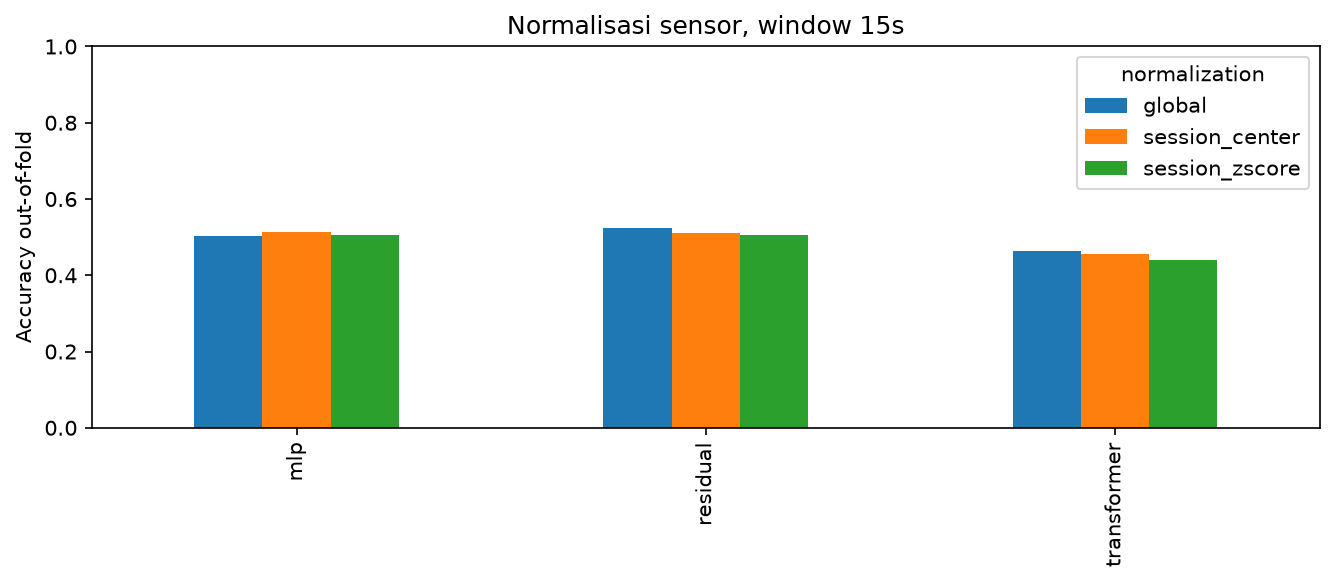

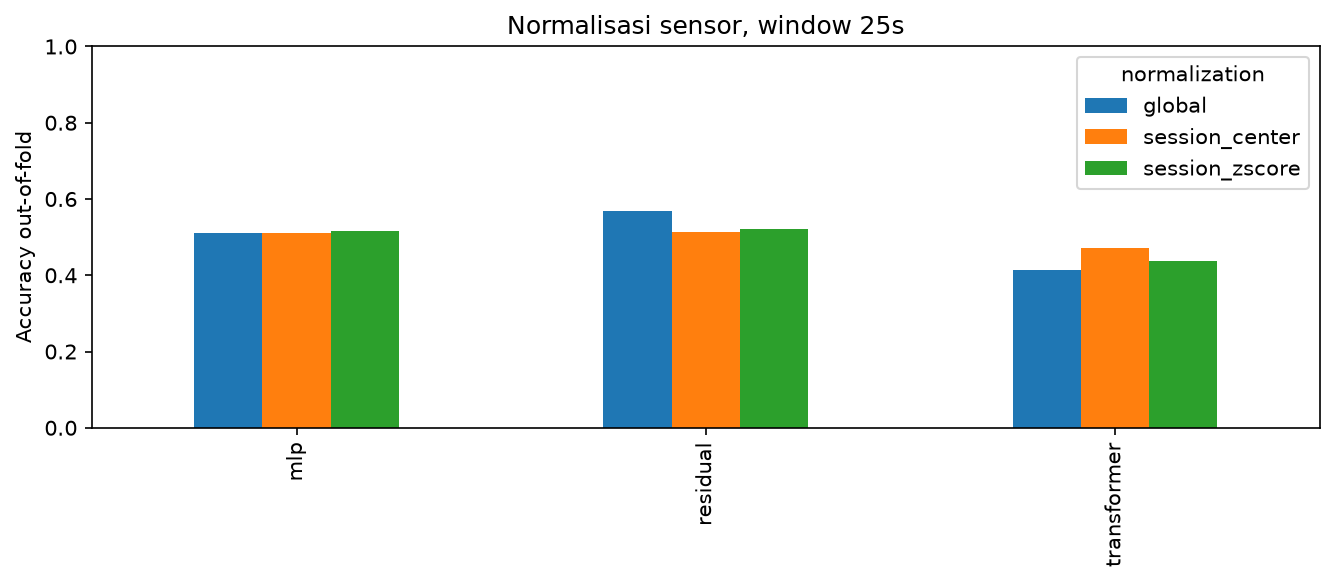

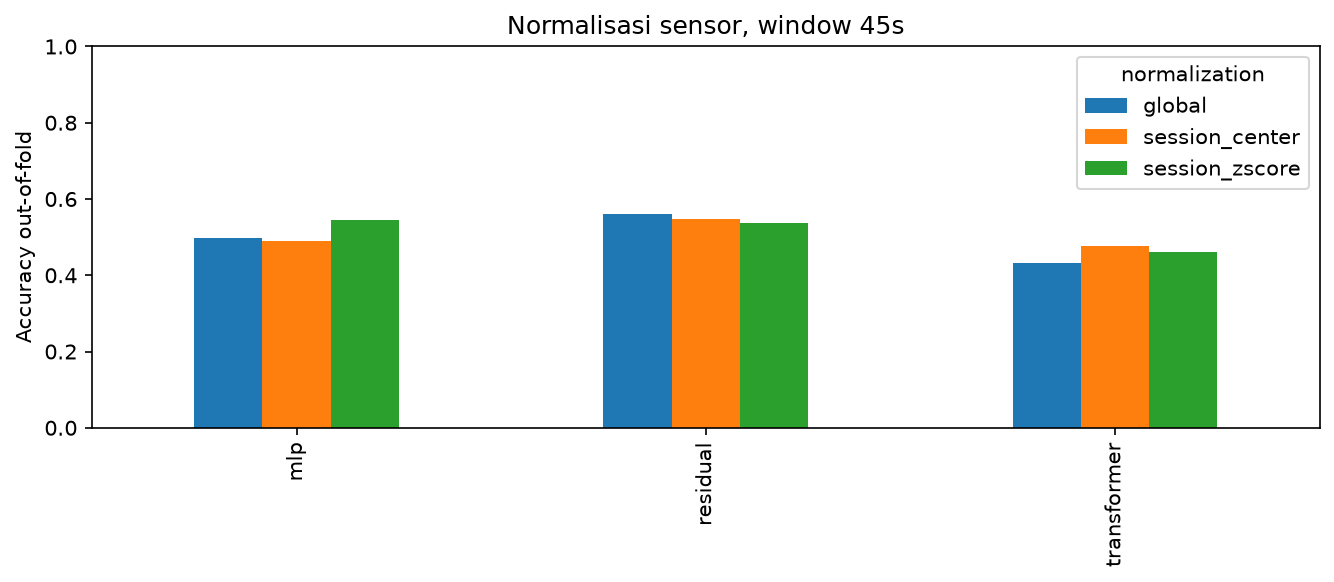

,id,window,stage,family,normalization,group,balance,accuracy,macro_f1,balanced_accuracy,accuracy_mean,accuracy_std,accuracy_min,training_accuracy,oof_rows
0,w15_699e7ac62841519a404b,15,neural_screening,residual,global,nonspatial,none,0.5462,0.5434,0.5436,0.5466,0.0424,0.4844,0.7634,2069
1,w15_72d3dbe0e85b7379bcba,15,neural_screening,residual,global,fusion,none,0.5230,0.5230,0.5219,0.5231,0.0675,0.4508,0.8044,2069
2,w15_381e028a5c20a83eb09e,15,neural_screening,mlp,session_center,fusion,none,0.5123,0.5060,0.5057,0.5122,0.0637,0.4029,0.6529,2069
3,w15_8c78095bb08862f3c7e2,15,neural_screening,residual,session_center,fusion,none,0.5109,0.5068,0.5063,0.5110,0.0452,0.4521,0.7690,2069
4,w15_c653423ce84676cdc9ed,15,neural_screening,residual,session_zscore,fusion,none,0.5060,0.5044,0.5043,0.5062,0.0645,0.4423,0.7441,2069
5,w15_daa09cf9d031fcd4d0b4,15,neural_screening,mlp,session_zscore,fusion,none,0.5056,0.4928,0.4967,0.5056,0.0566,0.4363,0.6469,2069
6,w15_6c4fba0dfe92739dade2,15,neural_screening,mlp,global,fusion,none,0.5041,0.5023,0.5029,0.5040,0.0318,0.4676,0.7096,2069
7,w15_c42ad132ba5f95da7d25,15,neural_screening,mlp,global,nonspatial,none,0.4674,0.4542,0.4564,0.4675,0.0433,0.3981,0.5960,2069
8,w15_474732bbb9e49d1dd4de,15,neural_screening,transformer,global,fusion,none,0.4630,0.4639,0.4643,0.4632,0.0417,0.4029,0.5948,2069
9,w15_4543be490573eb440b74,15,neural_screening,transformer,session_center,fusion,none,0.4563,0.4494,0.4490,0.4566,0.0525,0.3656,0.5834,2069


In [12]:
for window in (15, 25, 45):
    run_candidate(window, dummy_recipe(), "baseline")
    for architecture in ("mlp", "residual", "transformer"):
        for normalization in NORMALIZATIONS:
            for group in ("fusion", "nonspatial"):
                recipe = neural_recipe(architecture, normalization)
                recipe["group"] = group
                run_candidate(window, recipe, "neural_screening")
normalization_report(store, records)
display(validation_table(list(records.values())).round(4))

## Optimasi Konfigurasi

Pemimpin setiap normalisasi mendapat anggaran optimasi tersendiri. Fitur relatif dan balanced class weight dibandingkan sebagai konfigurasi tambahan. Class weight dihitung dari training saja. Seluruh pemilihan tahap ini menggunakan hasil internal Train; validation akhir dan test belum digunakan.

regularization / w15_678635079050589a88c7 / fold 1/5
  epoch 1: train_loss=1.0639, monitor_accuracy=0.4558
  epoch 10: train_loss=0.7679, monitor_accuracy=0.5680
  epoch 20: train_loss=0.6414, monitor_accuracy=0.6156
  epoch 30: train_loss=0.5398, monitor_accuracy=0.5986
  epoch 40: train_loss=0.4644, monitor_accuracy=0.5714
  epoch 1: train_loss=1.0762
  epoch 10: train_loss=0.7548
  epoch 20: train_loss=0.6104
regularization / w15_678635079050589a88c7 / fold 2/5
  epoch 1: train_loss=1.0685, monitor_accuracy=0.3133
  epoch 10: train_loss=0.6809, monitor_accuracy=0.4067
  epoch 20: train_loss=0.5725, monitor_accuracy=0.4400
  epoch 30: train_loss=0.4888, monitor_accuracy=0.4367
  epoch 1: train_loss=1.0676
  epoch 10: train_loss=0.7190
regularization / w15_678635079050589a88c7 / fold 3/5
  epoch 1: train_loss=1.0596, monitor_accuracy=0.3868
  epoch 10: train_loss=0.6783, monitor_accuracy=0.4460
  epoch 20: train_loss=0.5111, monitor_accuracy=0.4286
  epoch 1: train_loss=1.0642
regular

,id,window,stage,family,normalization,group,balance,accuracy,macro_f1,balanced_accuracy,accuracy_mean,accuracy_std,accuracy_min,training_accuracy,oof_rows
0,w15_eedb175e36fe256ea804,15,class_weight,residual,global,nonspatial,weight,0.5491,0.5474,0.5485,0.5496,0.0529,0.4724,0.7417,2069
1,w15_699e7ac62841519a404b,15,neural_screening,residual,global,nonspatial,none,0.5462,0.5434,0.5436,0.5466,0.0424,0.4844,0.7634,2069
2,w15_acd3400d4896b80b56df,15,regularization,residual,global,nonspatial,none,0.5442,0.5408,0.5424,0.5447,0.0586,0.4724,0.7130,2069
3,w15_678635079050589a88c7,15,regularization,residual,global,nonspatial,none,0.5394,0.5362,0.5366,0.5398,0.0377,0.4916,0.7609,2069
4,w15_d4ad92f9d4da71ab26a7,15,relative_features,residual,session_zscore,relative,none,0.5268,0.5257,0.5255,0.5269,0.0439,0.4929,0.7843,2069
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,w45_5b0ddd022d4ad45605d6,45,neural_screening,transformer,session_zscore,nonspatial,none,0.4024,0.3791,0.3977,0.4031,0.0892,0.3000,0.5345,1444
89,w45_f8b4af55eb21068578c5,45,neural_screening,mlp,session_center,nonspatial,none,0.3961,0.3869,0.3935,0.3949,0.0936,0.2407,0.5387,1444
90,w45_dbff3c3c2085acfde469,45,neural_screening,transformer,session_center,nonspatial,none,0.3650,0.3585,0.3624,0.3643,0.0671,0.2778,0.5854,1444
91,w45_8edaef2dc18a60c2a21d,45,neural_screening,transformer,global,nonspatial,none,0.3594,0.3573,0.3585,0.3629,0.0816,0.2305,0.5978,1444


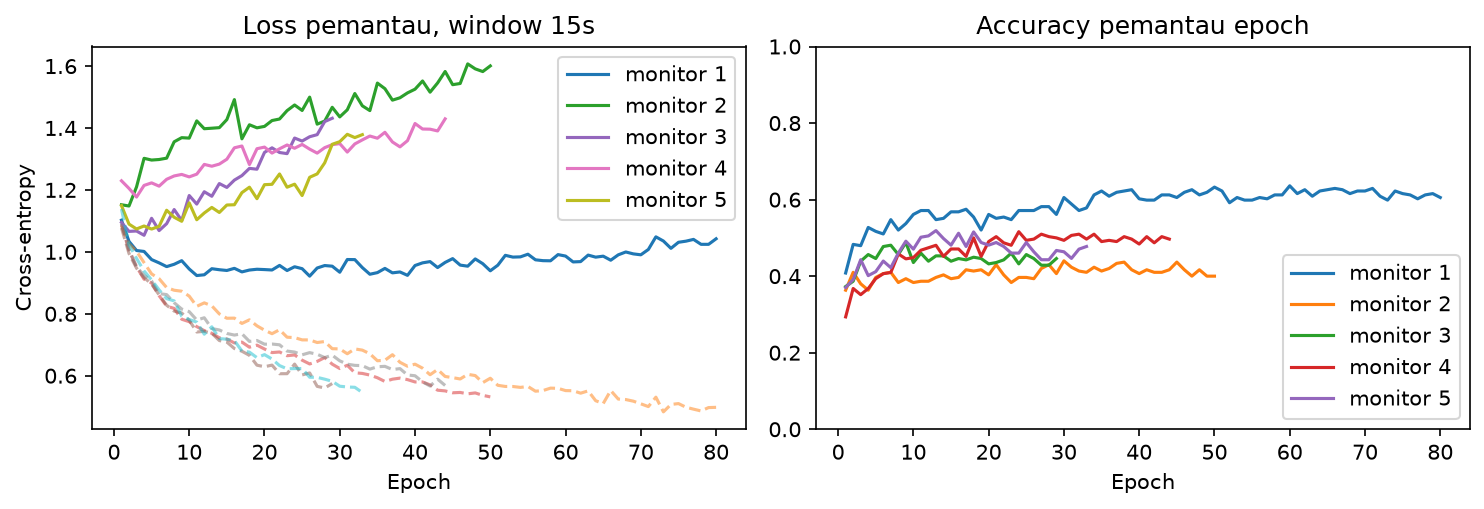

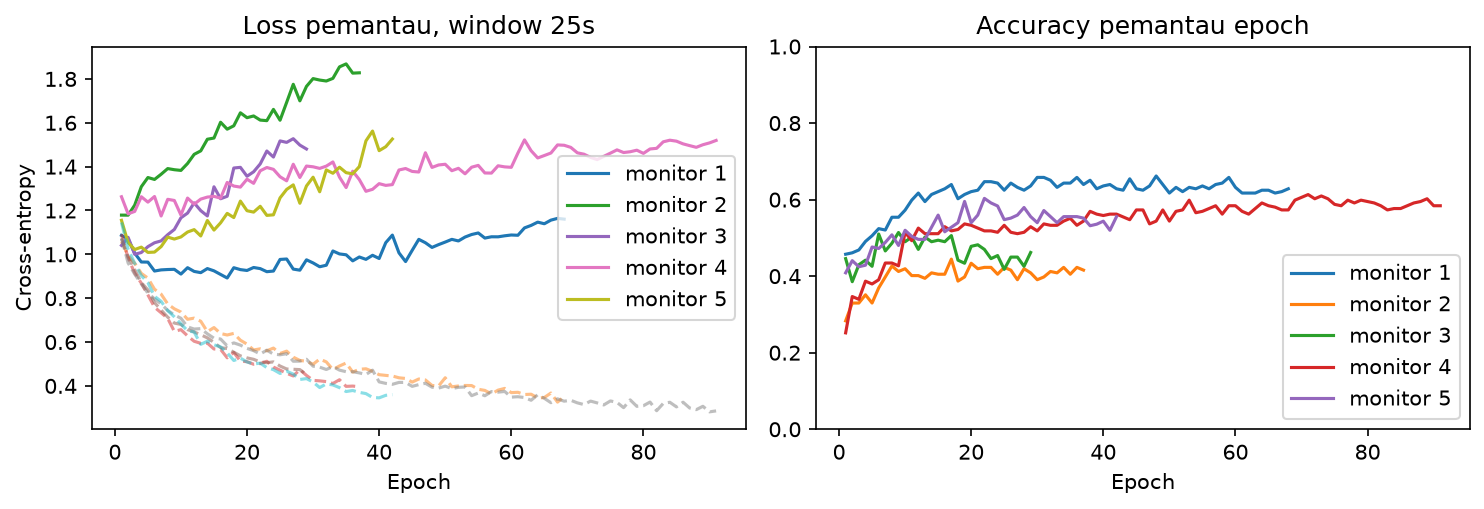

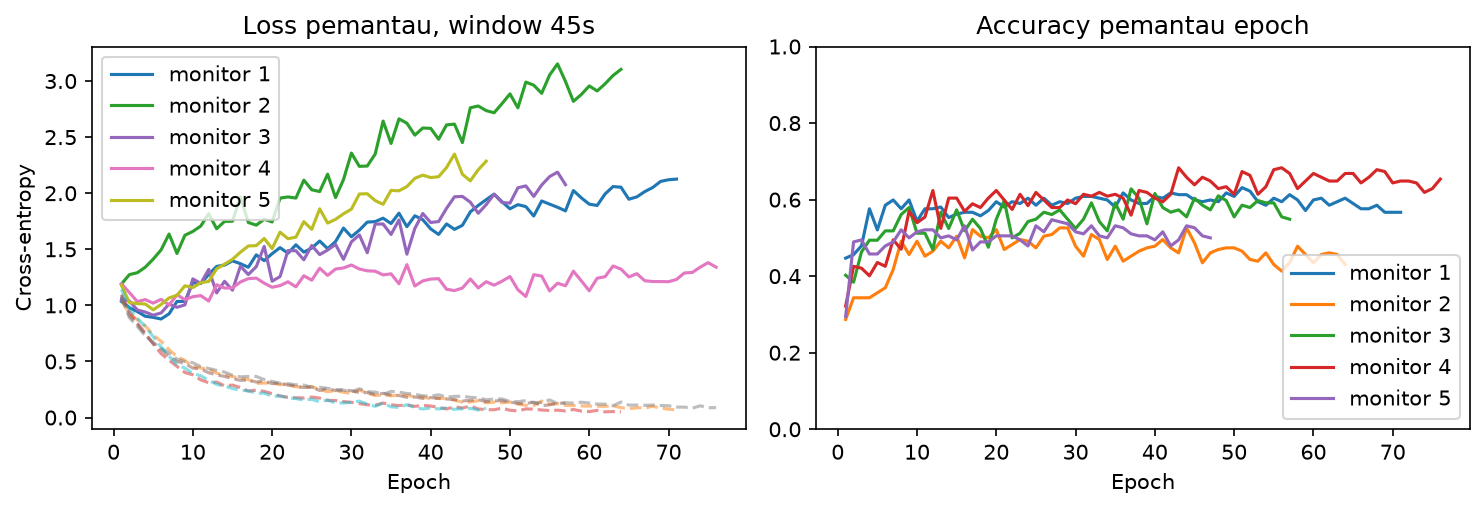

In [13]:
for window in (15, 25, 45):
    leaders = normalization_leaders(for_window(records, window))
    for leader in leaders:
        for dropout, decay, smoothing in ((0.1, 1e-4, 0.0), (0.5, 1e-2, 0.05)):
            recipe = copy.deepcopy(leader["recipe"])
            recipe["config"].update(
                dropout=dropout, weight_decay=decay, label_smoothing=smoothing
            )
            run_candidate(window, recipe, "regularization")
    for leader in normalization_leaders(for_window(records, window)):
        recipe = copy.deepcopy(leader["recipe"])
        recipe["group"] = "relative"
        run_candidate(window, recipe, "relative_features")
    for leader in normalization_leaders(for_window(records, window)):
        recipe = copy.deepcopy(leader["recipe"])
        recipe["balance"] = "weight"
        run_candidate(window, recipe, "class_weight")
display(validation_table(list(records.values())).round(4))
learning_curves(store, records)

## Seleksi Model Akhir

Maksimal dua arsitektur berbeda per normalisasi dilatih pada seluruh Train. Durasi memakai median epoch terbaik lima fold. Model seed 42 dibandingkan dengan rata-rata probabilitas seed 42, 43, dan 44 pada validation akhir.

Accuracy validation akhir menjadi kriteria utama, diikuti Macro-F1, minimum accuracy fold internal, jumlah komponen, dan jumlah fitur. Bentuk model individual atau ensemble yang akan disimpan dinilai langsung pada tahap ini.

In [14]:
finalists = fit_finalists(
    store, views, records, fit_neural, predict_neural, neural=True
)
display(
    pd.DataFrame(
        [
            {"window": r["window"], "id": r["id"], "kind": r["kind"], **r["validation"]}
            for r in finalists
        ]
    ).round(4)
)

Fitting seluruh Train / w15_eedb175e36fe256ea804 / seed 42
  epoch 1: train_loss=1.0636
  epoch 10: train_loss=0.8037
  epoch 20: train_loss=0.6894
Fitting seluruh Train / w15_eedb175e36fe256ea804 / seed 43
  epoch 1: train_loss=1.0726
  epoch 10: train_loss=0.7981
  epoch 20: train_loss=0.7292
Fitting seluruh Train / w15_eedb175e36fe256ea804 / seed 44
  epoch 1: train_loss=1.0668
  epoch 10: train_loss=0.7942
  epoch 20: train_loss=0.7007
Fitting seluruh Train / w15_d4ad92f9d4da71ab26a7 / seed 42
  epoch 1: train_loss=1.1254
  epoch 10: train_loss=0.8918
  epoch 20: train_loss=0.8132
  epoch 30: train_loss=0.7331
Fitting seluruh Train / w15_d4ad92f9d4da71ab26a7 / seed 43
  epoch 1: train_loss=1.0874
  epoch 10: train_loss=0.9068
  epoch 20: train_loss=0.8118
  epoch 30: train_loss=0.7674
Fitting seluruh Train / w15_d4ad92f9d4da71ab26a7 / seed 44
  epoch 1: train_loss=1.1101
  epoch 10: train_loss=0.9009
  epoch 20: train_loss=0.8273
  epoch 30: train_loss=0.7400
Fitting seluruh Train 

,id,window,kind,components,parents,accuracy,macro_f1,balanced_accuracy,training_accuracy,inner_min_accuracy,features
0,selection_w15_6776e23cf3ae14daadbd,15,probability_average,3,w15_eedb175e36fe256ea804,0.5804,0.5770,0.5833,0.7463,0.4724,11
1,selection_w15_6ed60b6923ffb7e9a620,15,single,1,w15_eedb175e36fe256ea804,0.5804,0.5758,0.5834,0.7448,0.4724,11
2,selection_w15_8ded99fd65bee6ab10b5,15,probability_average,3,w15_6c4fba0dfe92739dade2,0.5786,0.5790,0.5791,0.7796,0.4676,23
3,selection_w15_4d7eeb536d9bf72a9997,15,single,1,w15_6c4fba0dfe92739dade2,0.5518,0.5510,0.5501,0.7622,0.4676,23
4,selection_w15_bdb580f538039e4c23b9,15,probability_average,3,w15_381e028a5c20a83eb09e,0.4732,0.4669,0.4672,0.6597,0.4029,23
5,selection_w15_0155ff8f6dbff554cc2b,15,single,1,w15_daa09cf9d031fcd4d0b4,0.4732,0.4662,0.4668,0.6858,0.4363,23
6,selection_w15_cc1095c639a35203cff8,15,single,1,w15_381e028a5c20a83eb09e,0.4732,0.4660,0.4669,0.6607,0.4029,23
7,selection_w15_e62f55190f87c221f4b4,15,probability_average,3,w15_8c78095bb08862f3c7e2,0.4714,0.4697,0.4701,0.7487,0.4521,23
8,selection_w15_2997dc414a94c0e30980,15,single,1,w15_d4ad92f9d4da71ab26a7,0.4696,0.4649,0.4651,0.7728,0.4929,27
9,selection_w15_47f28cf3ff8f2e2a39f7,15,single,1,w15_8c78095bb08862f3c7e2,0.4661,0.4660,0.4663,0.7496,0.4521,23


,window,id,kind,accuracy,macro_f1,balanced_accuracy
0,15,selection_w15_6776e23cf3ae14daadbd,probability_average,0.5804,0.5770,0.5833
1,25,selection_w25_93ca4e8852cae3795915,single,0.6094,0.6026,0.6026
2,45,selection_w45_7619ce58dca40be5ec37,probability_average,0.6649,0.6385,0.6383


## Evaluasi Test

Pilihan per-window dan model utama dikunci dari validation akhir sebelum test dibuka. Model test identik dengan model pada seleksi akhir, tanpa fitting ulang. Classification report dan confusion matrix memperlihatkan precision, recall, dan F1 tiap kelas. Hasil out-of-fold, validation akhir, dan test dilaporkan terpisah.

Window 15s: test accuracy=37.93%, Macro-F1=36.06%


,precision,recall,f1-score,support
Low,0.3333,0.3546,0.3436,141.0000
Medium,0.2842,0.1561,0.2015,173.0000
High,0.4521,0.6600,0.5366,150.0000
accuracy,0.3793,0.3793,0.3793,0.3793
macro avg,0.3565,0.3902,0.3606,464.0000
weighted avg,0.3534,0.3793,0.3530,464.0000


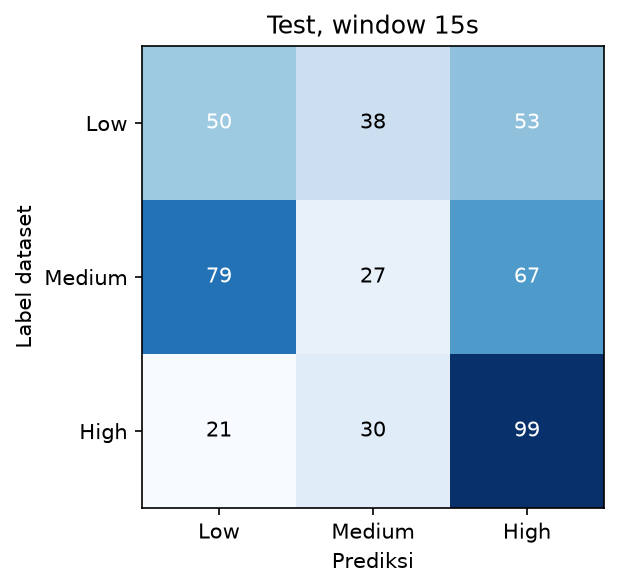

Window 25s: test accuracy=35.22%, Macro-F1=34.06%


,precision,recall,f1-score,support
Low,0.3611,0.2932,0.3237,133.0000
Medium,0.2830,0.1863,0.2247,161.0000
High,0.3828,0.6202,0.4734,129.0000
accuracy,0.3522,0.3522,0.3522,0.3522
macro avg,0.3423,0.3666,0.3406,423.0000
weighted avg,0.3380,0.3522,0.3317,423.0000


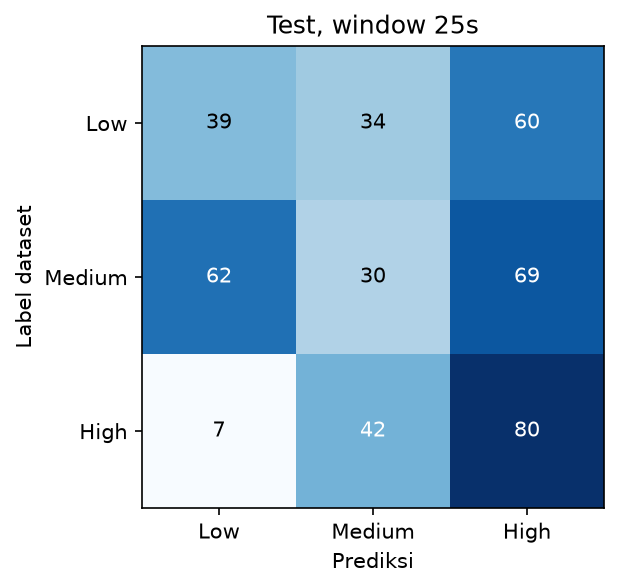

Window 45s: test accuracy=44.08%, Macro-F1=43.83%


,precision,recall,f1-score,support
Low,0.5250,0.5040,0.5143,125.0000
Medium,0.3303,0.3273,0.3288,110.0000
High,0.4587,0.4854,0.4717,103.0000
accuracy,0.4408,0.4408,0.4408,0.4408
macro avg,0.4380,0.4389,0.4383,338.0000
weighted avg,0.4414,0.4408,0.4409,338.0000


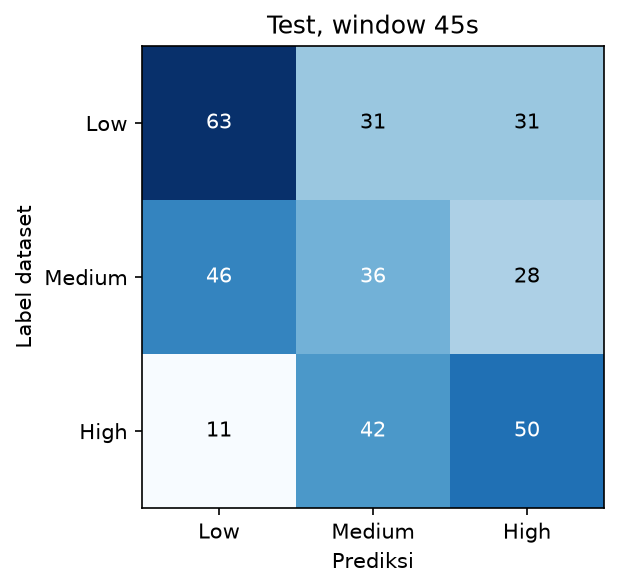

# Hasil Batch-04

Model utama: window 45 detik, dipilih dari validation akhir.

- Accuracy test: 44.08%
- Macro-F1 test: 43.83%
- Balanced accuracy test: 43.89%

Model test identik dengan model pada validation akhir. Tidak ada refit setelah seleksi. Evaluasi internal memakai blok waktu campuran dengan purge 45 detik. Dataset dan test pernah digunakan pada eksperimen terdahulu.

Model: final_selection_w45_7619ce58dca40be5ec37/model.pkl. Jenis skor: probability.



,window,primary,test_rows,training_accuracy,selection_accuracy,selection_macro_f1,accuracy,macro_f1,balanced_accuracy
0,15,False,464,0.7463,0.5804,0.5770,0.3793,0.3606,0.3902
1,25,False,423,0.7935,0.6094,0.6026,0.3522,0.3406,0.3666
2,45,True,338,0.9765,0.6649,0.6385,0.4408,0.4383,0.4389


In [15]:
test_summary = final_evaluation(store, views, finalists, predict_neural)
display(test_summary.round(4))

## Prediksi dengan Model Tersimpan

Bundle memuat classifier, urutan fitur, preprocessing, dan acuan normalisasi training. Metadata sesi digunakan untuk memilih acuan, bukan sebagai predictor. Gunakan hanya artefak model yang terpercaya.

In [16]:
selected = store.read("selection")
model = load_bundle(store.artifact("final_" + selected["primary_id"], "model.pkl"))
example = outer_frame(views[selected["primary_window"]], "test").head(3)
prediction = predict_neural(model, example)
display(
    pd.DataFrame(
        {
            "label": np.asarray(LABELS)[prediction["labels"]],
            **{
                f"{prediction['score_type']}_{label}": prediction["scores"][:, i]
                for i, label in enumerate(LABELS)
            },
        }
    )
)

,label,probability_Low,probability_Medium,probability_High
0,Medium,0.000706,0.997600,0.001695
1,Medium,0.000494,0.997553,0.001953
2,Medium,0.000821,0.997775,0.001403
